<a href="https://colab.research.google.com/github/atlassss1/Perfil-de-viagens/blob/main/Analise%20studant%20performance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import zipfile
import pandas as pd
import urllib.request
import os

# Baixar o dataset caso não exista localmente
url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
zip_path = "/content/student.zip"

if not os.path.exists(zip_path):
    print("Baixando o dataset...")
    urllib.request.urlretrieve(url, zip_path)
    print("Download concluído!")

# Extrair o arquivo principal que contém o zip que queremos
with zipfile.ZipFile(zip_path, "r") as arquivo_zip:
    arquivo_zip.extractall("/content/temp_student")

# O arquivo baixado contém outro zip dentro ('student.zip')
with zipfile.ZipFile("/content/temp_student/student.zip", "r") as arquivo_zip_interno:
    arquivo_zip_interno.extractall("/content/student")

# Carregar o dataset
df = pd.read_csv(
    "/content/student/student-mat.csv",
    sep=";"
)

print("Dataset carregado com sucesso!")
print("Linhas e colunas:", df.shape)

display(df.head())

Dataset carregado com sucesso!
Linhas e colunas: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:

# 1. Visualizar os primeiros registros
display(df.head())

# 2. Verificar o tamanho do conjunto de dados
print("Quantidade de linhas e colunas:", df.shape)

# 3. Verificar os tipos de dados
print("\nTipos de dados:")
print(df.dtypes)

# 4. Verificar valores ausentes
print("\nValores ausentes por coluna:")
print(df.isnull().sum())

# 5. Verificar registros duplicados
print("\nRegistros duplicados:", df.duplicated().sum())

# 6. Estatísticas descritivas
print("\nEstatísticas descritivas:")
display(df.describe().T)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Quantidade de linhas e colunas: (395, 33)

Tipos de dados:
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object

Valores ausentes por coluna:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime  

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


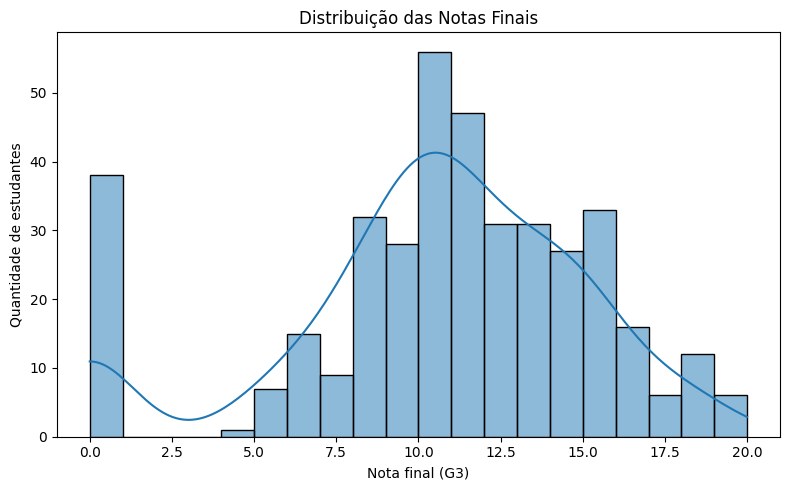

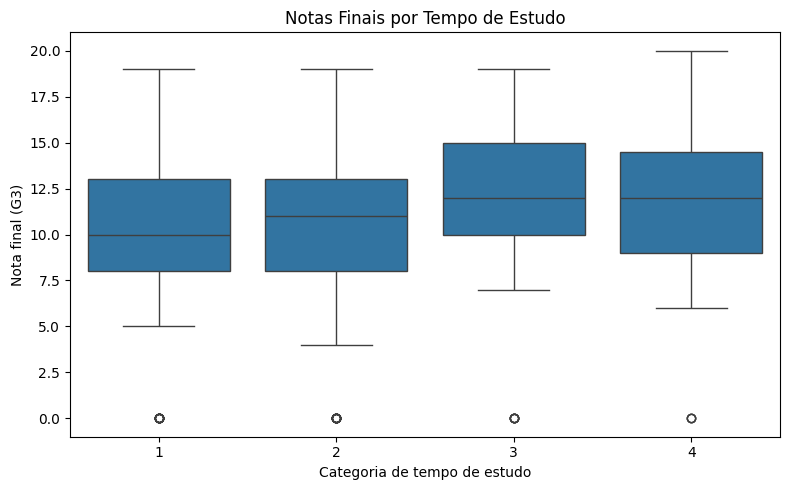

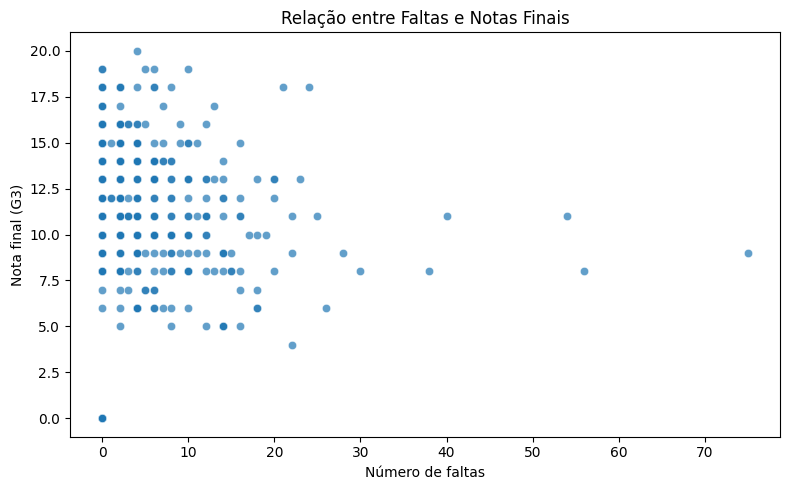

In [5]:

import matplotlib.pyplot as plt
import seaborn as sns

# Gráfico 1: distribuição das notas finais
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="G3", bins=20, kde=True)
plt.title("Distribuição das Notas Finais")
plt.xlabel("Nota final (G3)")
plt.ylabel("Quantidade de estudantes")
plt.tight_layout()
plt.show()

# Gráfico 2: notas finais por tempo de estudo
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="studytime", y="G3")
plt.title("Notas Finais por Tempo de Estudo")
plt.xlabel("Categoria de tempo de estudo")
plt.ylabel("Nota final (G3)")
plt.tight_layout()
plt.show()

# Gráfico 3: relação entre faltas e notas finais
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="absences", y="G3", alpha=0.7)
plt.title("Relação entre Faltas e Notas Finais")
plt.xlabel("Número de faltas")
plt.ylabel("Nota final (G3)")
plt.tight_layout()
plt.show()


Estatísticas das notas finais (G3):
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

Estatísticas das faltas:
count    395.000000
mean       5.708861
std        8.003096
min        0.000000
25%        0.000000
50%        4.000000
75%        8.000000
max       75.000000
Name: absences, dtype: float64


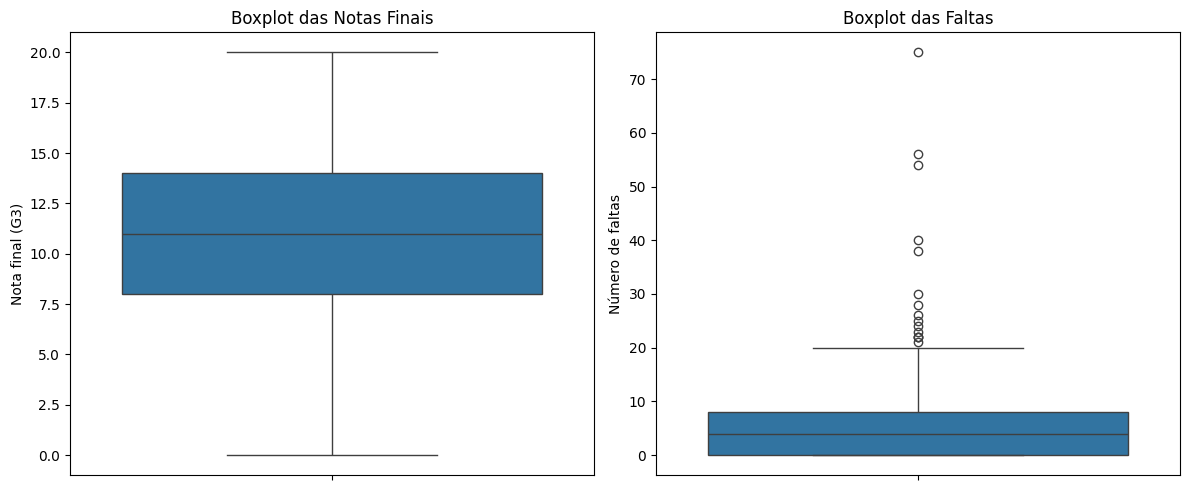

In [6]:

# Verificar estatísticas das notas e das faltas
print("Estatísticas das notas finais (G3):")
print(df["G3"].describe())

print("\nEstatísticas das faltas:")
print(df["absences"].describe())

# Boxplots para identificar possíveis valores atípicos
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, y="G3", ax=axes[0])
axes[0].set_title("Boxplot das Notas Finais")
axes[0].set_ylabel("Nota final (G3)")

sns.boxplot(data=df, y="absences", ax=axes[1])
axes[1].set_title("Boxplot das Faltas")
axes[1].set_ylabel("Número de faltas")

plt.tight_layout()
plt.show()


In [7]:

from sklearn.preprocessing import StandardScaler
import pandas as pd

# Criar uma cópia para preservar os dados originais
df_preparado = df.copy()

# Transformar variáveis categóricas em colunas numéricas
categoricas = df_preparado.select_dtypes(
    include=["object", "category"]
).columns.tolist()

df_codificado = pd.get_dummies(
    df_preparado,
    columns=categoricas,
    drop_first=True,
    dtype=int
)

print("Dimensões originais:", df.shape)
print("Dimensões após codificação:", df_codificado.shape)
print("Variáveis categóricas codificadas:", len(categoricas))

display(df_codificado.head())


Dimensões originais: (395, 33)
Dimensões após codificação: (395, 42)
Variáveis categóricas codificadas: 17


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,1,0,0,0,1,1,0,0
1,17,1,1,1,2,0,5,3,3,1,...,0,0,0,1,0,0,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,...,1,0,1,0,1,0,1,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,1,0,0,1,1,1,1,1,1,1
4,16,3,3,1,2,0,4,3,2,1,...,0,0,0,1,1,0,1,1,0,0


In [8]:

from sklearn.preprocessing import StandardScaler
import pandas as pd

# Selecionar as variáveis para o K-Means
variaveis_cluster = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

X_cluster = df[variaveis_cluster].copy()

# Padronizar as variáveis
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# Transformar novamente em DataFrame para facilitar a visualização
X_scaled = pd.DataFrame(
    X_scaled,
    columns=variaveis_cluster,
    index=df.index
)

print("Dimensões dos dados para o K-Means:", X_scaled.shape)
print("\nMédias após padronização:")
print(X_scaled.mean().round(2))

print("\nDesvios-padrão após padronização:")
print(X_scaled.std().round(2))

display(X_scaled.head())


Dimensões dos dados para o K-Means: (395, 6)

Médias após padronização:
age          0.0
studytime   -0.0
failures    -0.0
absences    -0.0
G1           0.0
G2          -0.0
dtype: float64

Desvios-padrão após padronização:
age          1.0
studytime    1.0
failures     1.0
absences     1.0
G1           1.0
G2           1.0
dtype: float64


,age,studytime,failures,absences,G1,G2
0,1.023046,-0.042286,-0.449944,0.036424,-1.782467,-1.254791
1,0.238380,-0.042286,-0.449944,-0.213796,-1.782467,-1.520979
2,-1.330954,-0.042286,3.589323,0.536865,-1.179147,-0.722415
3,-1.330954,1.150779,-0.449944,-0.464016,1.234133,0.874715
4,-0.546287,-0.042286,-0.449944,-0.213796,-1.480807,-0.190038


In [9]:

import zipfile
import pandas as pd

with zipfile.ZipFile("/content/student.zip", "r") as arquivo_zip:
    arquivo_zip.extractall("/content/student")

df = pd.read_csv(
    "/content/student/student-mat.csv",
    sep=";"
)

print("Dataset carregado com sucesso!")
print("Dimensões:", df.shape)

display(df.head())



Dataset carregado com sucesso!
Dimensões: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [10]:

import zipfile
import pandas as pd

with zipfile.ZipFile("/content/student.zip", "r") as arquivo_zip:
    arquivo_zip.extractall("/content/student")

df = pd.read_csv(
    "/content/student/student-mat.csv",
    sep=";"
)

print("Dataset carregado com sucesso!")
print("Dimensões:", df.shape)

display(df.head())


Dataset carregado com sucesso!
Dimensões: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [11]:

from sklearn.preprocessing import StandardScaler

variaveis_cluster = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

X_cluster = df[variaveis_cluster].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=variaveis_cluster,
    index=df.index
)

print("Dimensões dos dados para o K-Means:", X_scaled.shape)
display(X_scaled.head())


Dimensões dos dados para o K-Means: (395, 6)


,age,studytime,failures,absences,G1,G2
0,1.023046,-0.042286,-0.449944,0.036424,-1.782467,-1.254791
1,0.238380,-0.042286,-0.449944,-0.213796,-1.782467,-1.520979
2,-1.330954,-0.042286,3.589323,0.536865,-1.179147,-0.722415
3,-1.330954,1.150779,-0.449944,-0.464016,1.234133,0.874715
4,-0.546287,-0.042286,-0.449944,-0.213796,-1.480807,-0.190038


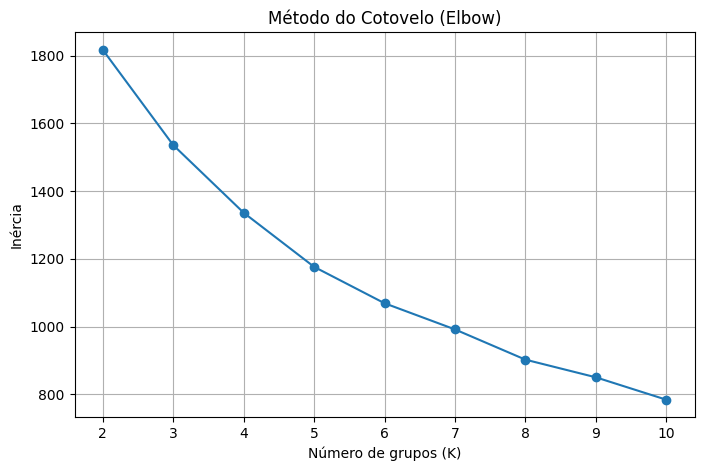

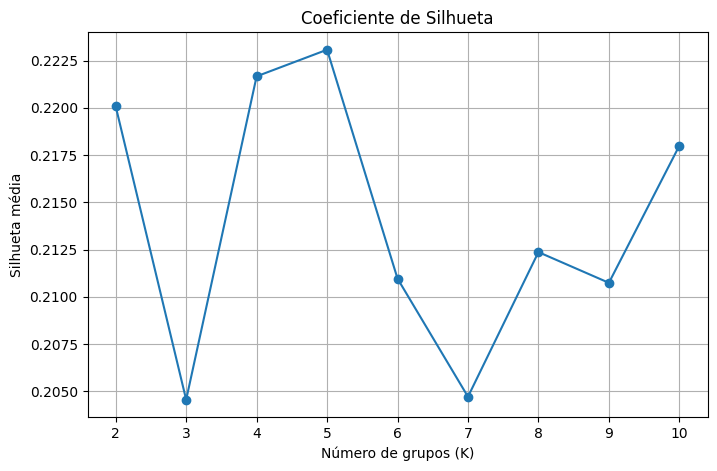

K=2: Inércia=1817.30 | Silhueta=0.2201
K=3: Inércia=1535.99 | Silhueta=0.2046
K=4: Inércia=1336.34 | Silhueta=0.2217
K=5: Inércia=1176.57 | Silhueta=0.2231
K=6: Inércia=1069.12 | Silhueta=0.2110
K=7: Inércia=991.83 | Silhueta=0.2047
K=8: Inércia=902.59 | Silhueta=0.2124
K=9: Inércia=850.46 | Silhueta=0.2107
K=10: Inércia=784.36 | Silhueta=0.2180


In [12]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Testar valores de K entre 2 e 10
valores_k = range(2, 11)
inercia = []
silhuetas = []

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    grupos = modelo.fit_predict(X_scaled)

    inercia.append(modelo.inertia_)
    silhuetas.append(
        silhouette_score(X_scaled, grupos)
    )

# Gráfico 1: método do cotovelo
plt.figure(figsize=(8, 5))
plt.plot(list(valores_k), inercia, marker="o")
plt.title("Método do Cotovelo (Elbow)")
plt.xlabel("Número de grupos (K)")
plt.ylabel("Inércia")
plt.xticks(list(valores_k))
plt.grid(True)
plt.show()

# Gráfico 2: coeficiente de silhueta
plt.figure(figsize=(8, 5))
plt.plot(list(valores_k), silhuetas, marker="o")
plt.title("Coeficiente de Silhueta")
plt.xlabel("Número de grupos (K)")
plt.ylabel("Silhueta média")
plt.xticks(list(valores_k))
plt.grid(True)
plt.show()

# Exibir os resultados numéricos
for k, ine, sil in zip(valores_k, inercia, silhuetas):
    print(f"K={k}: Inércia={ine:.2f} | Silhueta={sil:.4f}")


Quantidade de estudantes por grupo:
cluster
0     47
1     78
2    127
3    112
4     31
Name: count, dtype: int64


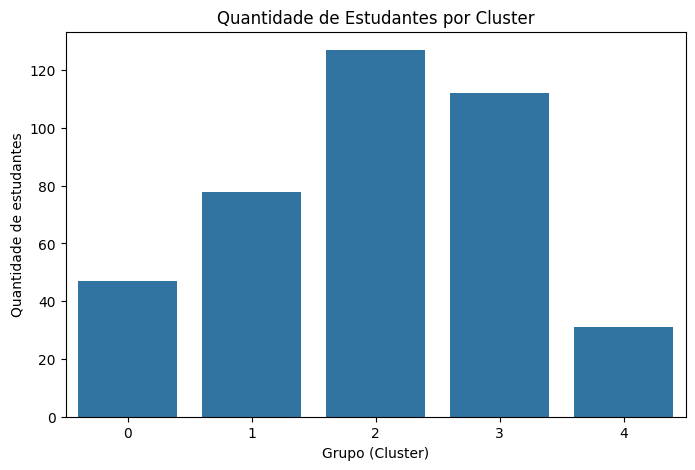

In [13]:

from sklearn.cluster import KMeans
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Criar e treinar o modelo com 5 grupos
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df["cluster"] = kmeans.fit_predict(X_scaled)

# Verificar quantos estudantes ficaram em cada grupo
print("Quantidade de estudantes por grupo:")
print(df["cluster"].value_counts().sort_index())

# Visualizar a distribuição dos grupos
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="cluster")
plt.title("Quantidade de Estudantes por Cluster")
plt.xlabel("Grupo (Cluster)")
plt.ylabel("Quantidade de estudantes")
plt.show()


Perfil médio dos estudantes por cluster:


,age,studytime,failures,absences,G1,G2,G3
cluster,,,,,,,
0,17.30,1.81,0.43,21.02,11.02,10.43,10.53
1,16.71,3.35,0.06,3.96,12.53,12.55,12.29
2,16.73,1.80,0.17,3.43,8.27,7.92,7.32
3,16.29,1.62,0.07,3.20,13.76,13.89,13.94
4,17.10,1.58,2.52,5.29,7.19,6.48,5.45


Quantidade por cluster:


,Quantidade
cluster,
0,47
1,78
2,127
3,112
4,31


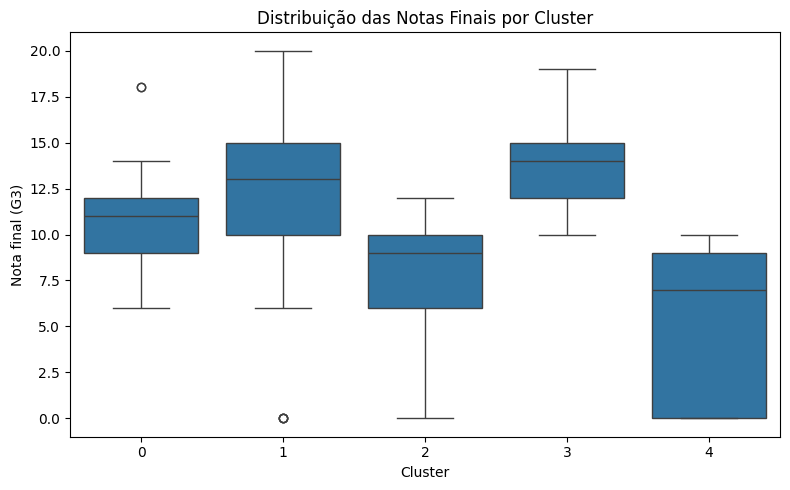

In [14]:

# Calcular as médias das variáveis em cada cluster
variaveis_perfil = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2",
    "G3"
]

perfil_clusters = df.groupby("cluster")[variaveis_perfil].mean().round(2)

print("Perfil médio dos estudantes por cluster:")
display(perfil_clusters)

# Quantidade de estudantes em cada grupo
print("Quantidade por cluster:")
display(df["cluster"].value_counts().sort_index().rename("Quantidade"))

# Visualizar as notas finais por grupo
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="cluster", y="G3")
plt.title("Distribuição das Notas Finais por Cluster")
plt.xlabel("Cluster")
plt.ylabel("Nota final (G3)")
plt.tight_layout()
plt.show()


In [15]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Variáveis de entrada
variaveis = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

X = df[variaveis]
y = df["G3"]

# Separar 80% para treino e 20% para teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Registros para treinamento:", X_train.shape[0])
print("Registros para teste:", X_test.shape[0])


Registros para treinamento: 316
Registros para teste: 79


In [16]:

# Treinar a Regressão Linear
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Prever as notas dos estudantes do conjunto de teste
y_pred = modelo.predict(X_test)

# Avaliar o modelo
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"R²: {r2:.4f}")

# Mostrar os coeficientes
coeficientes = pd.DataFrame({
    "Variável": X.columns,
    "Coeficiente": modelo.coef_
})

print("\nCoeficientes da regressão:")
display(coeficientes)

print(f"Intercepto: {modelo.intercept_:.2f}")


RMSE: 2.11
MAE: 1.33
R²: 0.7824

Coeficientes da regressão:


,Variável,Coeficiente
0,age,-0.175384
1,studytime,-0.056596
2,failures,-0.382583
3,absences,0.043197
4,G1,0.162729
5,G2,0.964039


Intercepto: 1.20


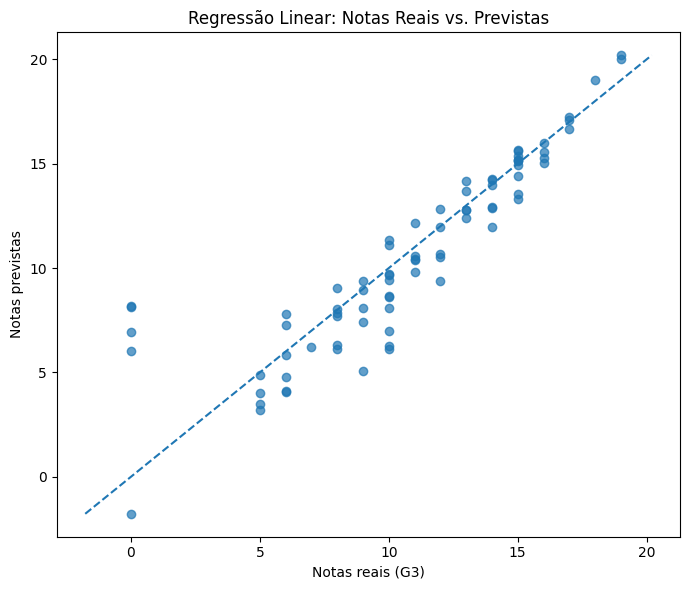

In [17]:

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Linha de previsões perfeitas
limite_min = min(y_test.min(), y_pred.min())
limite_max = max(y_test.max(), y_pred.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--"
)

plt.xlabel("Notas reais (G3)")
plt.ylabel("Notas previstas")
plt.title("Regressão Linear: Notas Reais vs. Previstas")
plt.tight_layout()
plt.show()


In [18]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
import pandas as pd

# Configurar validação cruzada com 5 divisões
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Métricas utilizadas
metricas = {
    "R2": "r2",
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error"
}

# Executar validação cruzada na Regressão Linear
resultados_cv = cross_validate(
    LinearRegression(),
    X_train,
    y_train,
    cv=cv,
    scoring=metricas
)

# Organizar os resultados
print("RESULTADOS DA VALIDAÇÃO CRUZADA")

print("R² médio:", resultados_cv["test_R2"].mean())
print("MAE médio:", -resultados_cv["test_MAE"].mean())
print("RMSE médio:", -resultados_cv["test_RMSE"].mean())

print("\nResultados por divisão:")

for i in range(5):
    print(
        f"Divisão {i+1}: "
        f"R² = {resultados_cv['test_R2'][i]:.4f} | "
        f"MAE = {-resultados_cv['test_MAE'][i]:.2f} | "
        f"RMSE = {-resultados_cv['test_RMSE'][i]:.2f}"
    )

RESULTADOS DA VALIDAÇÃO CRUZADA
R² médio: 0.8276766776790783
MAE médio: 1.190867186054367
RMSE médio: 1.8548547420706103

Resultados por divisão:
Divisão 1: R² = 0.8388 | MAE = 0.99 | RMSE = 1.52
Divisão 2: R² = 0.8010 | MAE = 1.63 | RMSE = 2.45
Divisão 3: R² = 0.7912 | MAE = 1.11 | RMSE = 1.71
Divisão 4: R² = 0.9052 | MAE = 0.92 | RMSE = 1.37
Divisão 5: R² = 0.8022 | MAE = 1.30 | RMSE = 2.22


In [21]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Criar o modelo de referência
modelo_baseline = DummyRegressor(strategy="mean")

# Treinar o modelo
modelo_baseline.fit(X_train, y_train)

# Fazer previsões
y_pred_baseline = modelo_baseline.predict(X_test)

# Avaliar o Baseline
rmse_baseline = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
mae_baseline = mean_absolute_error(y_test, y_pred_baseline)
r2_baseline = r2_score(y_test, y_pred_baseline)

# Comparar com a Regressão Linear já treinada
comparacao = pd.DataFrame({
    "Modelo": ["Regressão Linear", "Baseline"],
    "R²": [
        r2_score(y_test, y_pred),
        r2_baseline
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        rmse_baseline
    ],
    "MAE": [
        mean_absolute_error(y_test, y_pred),
        mae_baseline
    ]
})

print("COMPARAÇÃO DOS MODELOS")
display(comparacao)

COMPARAÇÃO DOS MODELOS


,Modelo,R²,RMSE,MAE
0,Regressão Linear,0.782392,2.112361,1.334018
1,Baseline,-0.009710,4.550181,3.645850
